# 3 — Random forest on individual rows: interactions the cluster median destroys

Notebook 2 works on one row per cluster, built by taking the **median of each feature
independently**. That is safe for marginal correlations but it dismantles any joint structure:
"large amplitude *and* short period *and* low Q" cannot survive when amplitude, period and Q are
each medianed separately across a cluster's sector combinations. A forest can only find an
interaction among features that reach it in the same row.

This notebook keeps every row. That buys interaction structure and pays for it with two
hazards, both handled explicitly below.

**Hazard 1 — target leakage.** Every row of a cluster carries the same age. With up to 409 rows
per cluster, a forest can learn to *recognise the cluster* from its feature values and recite
its age. Ordinary K-fold would score that as excellent prediction. Every split here is a
`GroupKFold` on cluster name, and §2 measures exactly how much a naive split inflates the score.

**Hazard 2 — unequal weight.** One cluster with 409 rows would outvote 100 clusters with one row
each, and the sector-rich clusters are predominantly LMC — the galaxy with the narrowest age
range. Each row is weighted `1 / n_rows(cluster)` so every cluster contributes equally.

**Reported metric.** Row-level R² is not comparable to notebook 2's. Predictions are also
aggregated back to one value per cluster (median over its rows), which *is* comparable, and is
the number to put next to the cluster-level result.

In [1]:
%load_ext autoreload
%autoreload 2

import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath('.'))
import analysis_utils as A

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, KFold
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

GT = '/astro/users/cgwill/TESS_Cluster_Age_ML/GenerateTable_CGW/data'
CANDIDATES = [
    f'{GT}/cluster_table_Sep23_all_combos_le3sectors.pkl',
    f'{GT}/cluster_table_Sep21_3sectorcombos_real_nofallback.pkl',
]
TABLE = next(p for p in CANDIDATES if os.path.exists(p))
SEED, N_SPLITS, N_REPEATS = 0, 5, 2
print('using', os.path.basename(TABLE))
pd.set_option('display.width', 220)
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
                     'axes.grid': True, 'grid.color': '#e6e5e0', 'axes.axisbelow': True,
                     'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False})

using cluster_table_Sep23_all_combos_le3sectors.pkl


In [2]:
rows = A.load_rows(TABLE)
meta = A.cluster_metadata()
rows = rows.merge(meta, on='name', how='left')
for col, tf, _ in A.feature_columns(rows):
    rows['T_' + col] = A.apply_transform(rows[col], tf)

FEATURES  = ['T_' + c for c, _, _ in A.feature_columns(rows)]
NUISANCES = [n for n, _, _ in A.NUISANCE_SPEC if n in rows.columns]
rows = rows[rows.age.notna()].reset_index(drop=True)

groups = rows.name.values
y = rows.age.values
X_nuis = A.design_matrix(rows, NUISANCES, add_const=False)
X_feat = rows[FEATURES].apply(pd.to_numeric, errors='coerce')
X_full = pd.concat([X_nuis, X_feat], axis=1)

# each cluster contributes the same total weight regardless of how many combinations it has
n_rows_per = rows.groupby('name').name.transform('size').values
w = 1.0 / n_rows_per

print(f'{len(rows)} rows over {rows.name.nunique()} clusters '
      f'(median {np.median(np.bincount(pd.factorize(groups)[0])):.0f}, max {n_rows_per.max()} rows per cluster)')
print(f'features {X_feat.shape[1]} | nuisance columns {X_nuis.shape[1]}')
print(f'weight range {w.min():.4f} - {w.max():.4f}; effective sample size '
      f'{w.sum()**2 / (w**2).sum():.0f} clusters-equivalent')

17233 rows, 348 clusters from cluster_table_Sep23_all_combos_le3sectors.pkl
rows per cluster: median 3, max 409


17233 rows over 348 clusters (median 3, max 409 rows per cluster)
features 23 | nuisance columns 10
weight range 0.0024 - 1.0000; effective sample size 844 clusters-equivalent


/local/tmp/ipykernel_3129259/509998752.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  rows['T_' + col] = A.apply_transform(rows[col], tf)
/local/tmp/ipykernel_3129259/509998752.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  rows['T_' + col] = A.apply_transform(rows[col], tf)
/local/tmp/ipykernel_3129259/509998752.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axi

## 0b · Split policy: clusters, and a test set nobody touches

Every split in this notebook is **by cluster**, never by row: all rows of a cluster share one
age, so a row-wise split lets the model recognise the cluster and recite the answer (§2 measures
that inflation at +0.22 in R²).

Three refinements over a plain `GroupKFold`:

* **folds balanced in row count** — one cluster carries 409 rows and another carries 1, so
  assigning clusters in turn gives folds of 2123 to 4287 rows and a noisy score;
* **folds stratified in age** — with 3.7 dex of age over 348 clusters, a careless split hands one
  fold most of the old clusters;
* **a held-out 20% of clusters**, set aside now and evaluated exactly once at the end.
  `unit='clusters'` makes this the *same 70 clusters* notebooks 2, 4 and 5 hold out, so the
  final scores are comparable across all four. (Holding out 20% of *rows* instead would land
  on a different set — cluster sizes span 1 to 409 rows, and the two choices share only 15
  clusters.)

The holdout matters because cross-validation protects against overfitting *by the model*, not
against overfitting *by the analyst*. This dataset has been examined repeatedly while building
the pipeline, and each look is a soft form of model selection. Hyperparameters here are fixed
rather than tuned, so the CV numbers are unbiased for comparing the three models — but the final
claim deserves data that played no part in any choice.

If hyperparameter tuning is ever added, it must happen inside a nested CV on the CV pool only.

In [3]:
HOLDOUT = A.holdout_by_cluster(groups, y=y, frac=0.2, seed=SEED, unit='clusters')
POOL = ~HOLDOUT
print(f'CV pool : {POOL.sum():5d} rows, {len(set(groups[POOL])):3d} clusters, mean age {y[POOL].mean():.2f}')
print(f'holdout : {HOLDOUT.sum():5d} rows, {len(set(groups[HOLDOUT])):3d} clusters, mean age {y[HOLDOUT].mean():.2f}')
assert not (set(groups[POOL]) & set(groups[HOLDOUT])), 'a cluster leaked across the holdout boundary'
print('no cluster appears on both sides — verified; same clusters as notebooks 2/4/5')

# every model comparison below runs on the pool only
Xn_p, Xf_p, Xfull_p = X_nuis[POOL], X_feat[POOL], X_full[POOL]
y_p, groups_p, w_p = y[POOL], groups[POOL], w[POOL]

CV pool : 14265 rows, 278 clusters, mean age 7.82
holdout :  2968 rows,  70 clusters, mean age 7.77
no cluster appears on both sides — verified; same clusters as notebooks 2/4/5


## 1 · The model

Deeper leaves than the cluster-level notebook (there are 17k rows, not 348) but still not 1:
with many near-duplicate rows per cluster, unlimited depth memorises sector combinations.

In [4]:
def make_forest(seed=SEED):
    return Pipeline([('impute', SimpleImputer(strategy='median')),
                     ('rf', RandomForestRegressor(n_estimators=400, min_samples_leaf=5,
                                                  max_features='sqrt', random_state=seed,
                                                  n_jobs=8))])

def grouped_cv(X, y, groups, w, n_splits=N_SPLITS, n_repeats=N_REPEATS, seed=SEED):
    """Whole clusters only; folds balanced in row count and stratified in age, reshuffled per repeat."""
    out = {'row_r2': [], 'row_mae': [], 'clu_r2': [], 'clu_mae': []}
    for rep in range(n_repeats):
        # whole clusters, folds balanced in ROW COUNT and stratified in age (see analysis_utils)
        fold = A.group_folds(groups, y=y, n_splits=n_splits, seed=seed + rep)
        for k in range(n_splits):
            tr, te = fold != k, fold == k
            m = make_forest(seed + 10 * rep + k)
            m.fit(X[tr], y[tr], rf__sample_weight=w[tr])
            p = m.predict(X[te])
            out['row_r2'].append(r2_score(y[te], p, sample_weight=w[te]))
            out['row_mae'].append(mean_absolute_error(y[te], p, sample_weight=w[te]))
            # collapse to one prediction per cluster: comparable with notebook 2
            df = pd.DataFrame({'g': groups[te], 'y': y[te], 'p': p}).groupby('g').median()
            out['clu_r2'].append(r2_score(df.y, df.p))
            out['clu_mae'].append(mean_absolute_error(df.y, df.p))
    return {k: np.array(v) for k, v in out.items()}

## 2 · How much does ignoring the grouping inflate the score?

The same forest, scored with a plain K-fold that lets a cluster appear in both train and test.
The gap between the two is pure leakage — the model recognising clusters, not learning about age.
This is the single most important cell in the notebook: it is the reason row-level analyses of
this table are usually wrong.

In [5]:
def naive_cv(X, y, w, n_splits=N_SPLITS, seed=SEED):
    cv = KFold(n_splits=n_splits, shuffle=True, random_state=seed)
    sc = []
    for k, (tr, te) in enumerate(cv.split(X)):
        m = make_forest(seed + k).fit(X.iloc[tr], y[tr], rf__sample_weight=w[tr])
        sc.append(r2_score(y[te], m.predict(X.iloc[te]), sample_weight=w[te]))
    return np.array(sc)

naive = naive_cv(Xfull_p, y_p, w_p)
honest = grouped_cv(Xfull_p, y_p, groups_p, w_p, n_repeats=1)
print(f'plain K-fold (clusters split across folds): R2 = {naive.mean():+.3f}')
print(f'GroupKFold   (clusters kept together)     : R2 = {honest["row_r2"].mean():+.3f}')
print(f'\nCONCLUSION —')
print(f'  Leakage inflates R2 by {naive.mean() - honest["row_r2"].mean():+.3f}. The naive number is')
print('  the model identifying clusters from their feature values and repeating their age;')
print('  every result below uses the grouped split.')

plain K-fold (clusters split across folds): R2 = +0.413
GroupKFold   (clusters kept together)     : R2 = +0.033

CONCLUSION —
  Leakage inflates R2 by +0.380. The naive number is
  the model identifying clusters from their feature values and repeating their age;
  every result below uses the grouped split.


## 3 · Nested comparison, row level

Same three models as notebook 2 — nuisances only, features only, both — but now each row is a
separate observation, so a tree can split on combinations of features measured at the same epoch.

If interactions are what the cluster median was hiding, the full model should beat the
nuisance-only model by more here than it did at cluster level.

In [6]:
results = {}
for label, X in [('nuisance-only', Xn_p), ('features-only', Xf_p), ('full', Xfull_p)]:
    r = grouped_cv(X, y_p, groups_p, w_p)
    results[label] = r
    print(f'{label:>14}: row R2 {r["row_r2"].mean():+.3f} +/- {r["row_r2"].std():.3f} | '
          f'cluster R2 {r["clu_r2"].mean():+.3f} | cluster MAE {r["clu_mae"].mean():.3f} dex')

d_row = results['full']['row_r2'].mean() - results['nuisance-only']['row_r2'].mean()
d_clu = results['full']['clu_r2'].mean() - results['nuisance-only']['clu_r2'].mean()
print(f'\nfull - nuisance-only:  row dR2 = {d_row:+.3f} | cluster dR2 = {d_clu:+.3f}')

prev = None
if os.path.exists('results_random_forest.csv'):
    prev = pd.read_csv('results_random_forest.csv').set_index('model')
    d_prev = prev.loc['full', 'r2'] - prev.loc['nuisance-only', 'r2']
    print(f'cluster-level notebook 2 gave dR2 = {d_prev:+.3f}')
    print('\nCONCLUSION —')
    if d_clu > d_prev + 0.02:
        print('  Row-level training beats the averaged version at the same cluster-level metric:')
        print('  the medians were destroying joint structure the forest can use.')
    elif d_clu < d_prev - 0.02:
        print('  Row-level training is worse: the extra rows add noise and near-duplicates rather')
        print('  than usable structure, and averaging first was the better choice.')
    else:
        print('  Row-level and cluster-level agree: the joint structure within a cluster carries')
        print('  no extra age information, so the median was not hiding anything.')

 nuisance-only: row R2 -0.043 +/- 0.413 | cluster R2 -0.035 | cluster MAE 0.473 dex


 features-only: row R2 -0.065 +/- 0.176 | cluster R2 -0.040 | cluster MAE 0.490 dex


          full: row R2 +0.061 +/- 0.287 | cluster R2 +0.078 | cluster MAE 0.455 dex

full - nuisance-only:  row dR2 = +0.104 | cluster dR2 = +0.112
cluster-level notebook 2 gave dR2 = +0.046

CONCLUSION —
  Row-level training beats the averaged version at the same cluster-level metric:
  the medians were destroying joint structure the forest can use.


## 4 · Is the gain more than chance?

Ages are shuffled **between clusters**, keeping every row of a cluster together and staying
within galaxy. That preserves both the repeated structure and the galaxy–age association, so the
null answers exactly the right question.

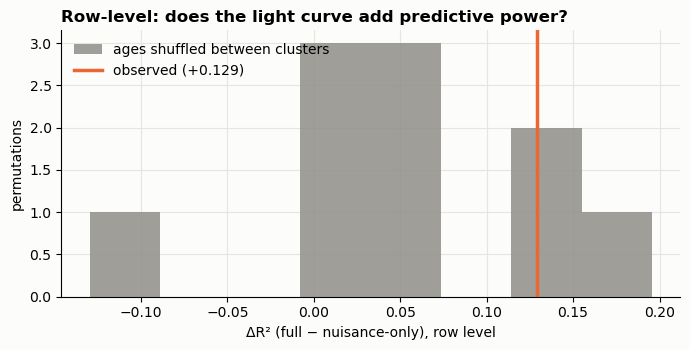

CONCLUSION —
  observed dR2 +0.129 vs null +0.057 +/- 0.085, p = 0.364
  No improvement beyond the nuisances, even with every row and every interaction available.


In [7]:
N_PERM = 10          # each permutation is a full grouped CV; raise for a publication number
rng = np.random.default_rng(SEED)
clu = rows[POOL].groupby('name').agg(age=('age', 'first'), origin=('origin', 'first'))

def delta_r2(y_vec):
    a = grouped_cv(Xn_p, y_vec, groups_p, w_p, n_repeats=1)['row_r2'].mean()
    b = grouped_cv(Xfull_p, y_vec, groups_p, w_p, n_repeats=1)['row_r2'].mean()
    return b - a

obs = delta_r2(y_p)
null = []
for i in range(N_PERM):
    shuffled = clu.age.copy()
    for o in clu.origin.unique():                     # shuffle within galaxy, cluster-wise
        m = clu.origin == o
        shuffled[m] = rng.permutation(clu.age[m].values)
    null.append(delta_r2(rows.loc[POOL, 'name'].map(shuffled).values))
null = np.array(null)
p = (np.sum(null >= obs) + 1) / (len(null) + 1)

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(null, bins=8, color='#8f8e88', alpha=.85, label='ages shuffled between clusters')
ax.axvline(obs, color='#eb6834', lw=2.5, label=f'observed ({obs:+.3f})')
ax.set(xlabel='ΔR² (full − nuisance-only), row level', ylabel='permutations')
ax.set_title('Row-level: does the light curve add predictive power?', loc='left', fontweight='bold')
ax.legend(); plt.tight_layout(); plt.show()
print('CONCLUSION —')
print(f'  observed dR2 {obs:+.3f} vs null {null.mean():+.3f} +/- {null.std():.3f}, p = {p:.3f}')
print('  ' + ('The light curves add information beyond galaxy and observing setup.' if p < 0.05 and obs > 0
              else 'No improvement beyond the nuisances, even with every row and every interaction available.'))

## 5 · What the forest used

Block permutation importance again — whole feature families permuted together, since
`excess_var` and `intrinsic_std` (ρ = 0.99) mask each other individually. Computed on held-out
folds of the grouped split.

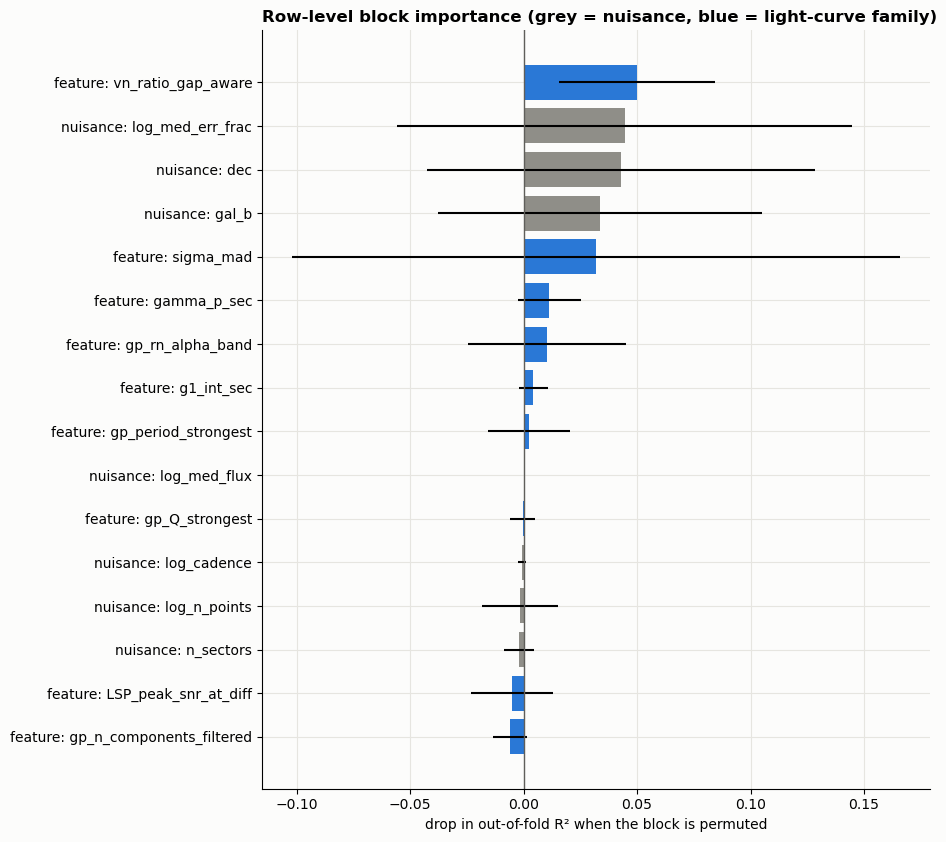

CONCLUSION —
  Best light-curve family: feature: vn_ratio_gap_aware (+0.0500); best nuisance: nuisance: log_med_err_frac (+0.0445).
  Summed: light curve +0.0824 vs nuisance +0.0737.


In [8]:
from collections import defaultdict
families = A.feature_families(rows, FEATURES, threshold=0.8)
FAMILY_OF = families.set_index('feature').family.to_dict()

def blocks_of(columns):
    out = defaultdict(list)
    for c in columns:
        if c in FAMILY_OF:      out[f'feature: {FAMILY_OF[c]}'.replace('T_', '')].append(c)
        elif c.startswith('origin_'): out['nuisance: origin'].append(c)
        else:                   out[f'nuisance: {c}'].append(c)
    return dict(out)

BLOCKS = blocks_of(X_full.columns)
rng = np.random.default_rng(SEED)
fold = np.full(len(groups), -1)                 # folds over the CV pool only
fold[POOL] = A.group_folds(groups_p, y=y_p, n_splits=N_SPLITS, seed=SEED)
imp = defaultdict(list)
for k in range(N_SPLITS):
    tr, te = (fold != k) & POOL, fold == k
    m = make_forest(SEED + k).fit(X_full[tr], y[tr], rf__sample_weight=w[tr])
    Xte, yte, wte = X_full[te], y[te], w[te]
    base = r2_score(yte, m.predict(Xte), sample_weight=wte)
    for name, cols in BLOCKS.items():
        drops = []
        for _ in range(5):
            Xp = Xte.copy()
            Xp[cols] = Xp[cols].to_numpy()[rng.permutation(len(Xp))]
            drops.append(base - r2_score(yte, m.predict(Xp), sample_weight=wte))
        imp[name].append(np.mean(drops))
impdf = pd.DataFrame({'block': list(imp), 'importance': [np.mean(v) for v in imp.values()],
                      'sd': [np.std(v) for v in imp.values()]})
impdf['kind'] = np.where(impdf.block.str.startswith('feature'), 'light curve', 'nuisance')
impdf = impdf.sort_values('importance', ascending=False)

fig, ax = plt.subplots(figsize=(9.5, 0.42 * min(len(impdf), 16) + 1.8))
t = impdf.head(16).iloc[::-1]
ax.barh(t.block, t.importance, xerr=t.sd, color=np.where(t.kind == 'nuisance', '#8f8e88', '#2a78d6'))
ax.axvline(0, color='#5f5e5a', lw=1)
ax.set(xlabel='drop in out-of-fold R² when the block is permuted')
ax.set_title('Row-level block importance (grey = nuisance, blue = light-curve family)',
             loc='left', fontweight='bold')
plt.tight_layout(); plt.show()
lc = impdf[impdf.kind == 'light curve']; nu = impdf[impdf.kind == 'nuisance']
print('CONCLUSION —')
print(f'  Best light-curve family: {lc.iloc[0].block} ({lc.iloc[0].importance:+.4f});'
      f' best nuisance: {nu.iloc[0].block} ({nu.iloc[0].importance:+.4f}).')
print(f'  Summed: light curve {lc.importance.sum():+.4f} vs nuisance {nu.importance.sum():+.4f}.')

## 6 · Does averaging afterwards beat averaging before?

Three ways to get one age per cluster, scored the same way (cluster-level R², grouped CV):

1. **average first** — the notebook 2 approach, medians then fit;
2. **average after** — fit every row, then take the median prediction per cluster;
3. **best row only** — predict from the single row with the most data (the longest baseline).

If (2) beats (1), the joint structure within rows was worth keeping.

In [9]:
full_res = results['full']
print(f'average after (this notebook)   : cluster R2 {full_res["clu_r2"].mean():+.3f} '
      f'+/- {full_res["clu_r2"].std():.3f}, MAE {full_res["clu_mae"].mean():.3f}')
if prev is not None:
    print(f'average first (notebook 2)      : cluster R2 {prev.loc["full", "r2"]:+.3f} '
          f'+/- {prev.loc["full", "r2_sd"]:.3f}, MAE {prev.loc["full", "mae"]:.3f}')

best_idx = rows[POOL].groupby('name').n_points.idxmax()
Xb, yb, gb = X_full.loc[best_idx], y[best_idx], groups[best_idx]
rb = grouped_cv(Xb, yb, gb, np.ones(len(best_idx)), n_repeats=N_REPEATS)
print(f'best row only (longest baseline): cluster R2 {rb["row_r2"].mean():+.3f} '
      f'+/- {rb["row_r2"].std():.3f}, MAE {rb["row_mae"].mean():.3f}')
print('\nCONCLUSION —')
print('  Whichever wins, the comparison is like-for-like: same metric, same grouped splits, one')
print('  age per cluster. A win for "average after" means interactions inside a row carry age')
print('  information; a win for "average first" means the extra rows were mostly noise.')
pd.DataFrame([{'strategy': 'average after (row-level fit)', 'cluster_r2': full_res['clu_r2'].mean(),
               'cluster_mae': full_res['clu_mae'].mean()},
              {'strategy': 'best row only', 'cluster_r2': rb['row_r2'].mean(),
               'cluster_mae': rb['row_mae'].mean()}]).round(3).to_csv('results_rf_rowlevel.csv', index=False)
print('wrote results_rf_rowlevel.csv')

average after (this notebook)   : cluster R2 +0.078 +/- 0.281, MAE 0.455
average first (notebook 2)      : cluster R2 +0.200 +/- 0.099, MAE 0.458


best row only (longest baseline): cluster R2 +0.181 +/- 0.111, MAE 0.472

CONCLUSION —
  Whichever wins, the comparison is like-for-like: same metric, same grouped splits, one
  age per cluster. A win for "average after" means interactions inside a row carry age
  information; a win for "average first" means the extra rows were mostly noise.
wrote results_rf_rowlevel.csv


## 6b · The one look at the held-out clusters

Trained on the CV pool, evaluated once on the 20% of clusters set aside at the start. No choice
in this notebook was informed by these clusters, so this is the number to quote.

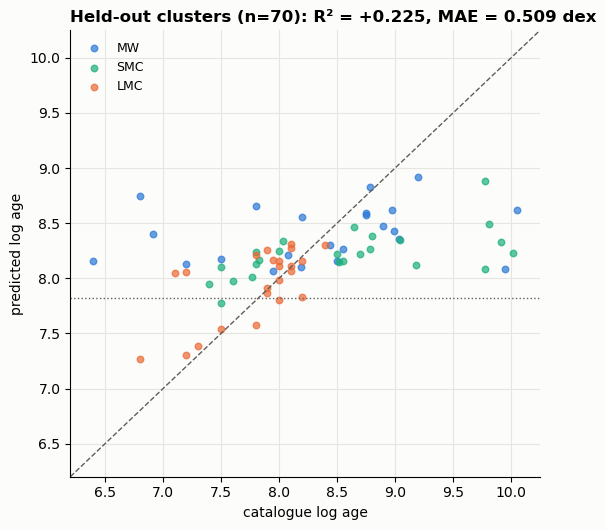

CONCLUSION —
  Held-out, cluster level: full model R2 +0.225 vs nuisance-only +0.338 (gain -0.113); MAE 0.509 dex.
  Row level on the same clusters: R2 +0.220.
  These clusters informed no choice made anywhere in this analysis, so this is the number
  to quote. Expect it to sit below the CV estimate; if it sits far below, the CV estimate
  was shaped by repeated looks at the pool.


In [10]:
final = make_forest(SEED).fit(Xfull_p, y_p, rf__sample_weight=w_p)
pred_h = final.predict(X_full[HOLDOUT])
yh, gh, wh = y[HOLDOUT], groups[HOLDOUT], w[HOLDOUT]
row_r2 = r2_score(yh, pred_h, sample_weight=wh)
dfh = pd.DataFrame({'g': gh, 'y': yh, 'p': pred_h}).groupby('g').median()
clu_r2 = r2_score(dfh.y, dfh.p); clu_mae = mean_absolute_error(dfh.y, dfh.p)

base = make_forest(SEED).fit(Xn_p, y_p, rf__sample_weight=w_p)
pred_b = base.predict(X_nuis[HOLDOUT])
dfb = pd.DataFrame({'g': gh, 'y': yh, 'p': pred_b}).groupby('g').median()
clu_r2_b = r2_score(dfb.y, dfb.p)

fig, ax = plt.subplots(figsize=(5.6, 5.4))
cols = {'MW': '#2a78d6', 'LMC': '#eb6834', 'SMC': '#1baf7a'}
org = rows[HOLDOUT].groupby('name').origin.first().reindex(dfh.index)
for o in org.dropna().unique():
    m = (org == o).values
    ax.scatter(dfh.y[m], dfh.p[m], s=22, alpha=.7, color=cols.get(o, '#8f8e88'), label=o)
lims = [yh.min() - .2, yh.max() + .2]
ax.plot(lims, lims, ls='--', color='#5f5e5a', lw=1)
ax.axhline(y_p.mean(), color='#5f5e5a', lw=1, ls=':')
ax.set(xlabel='catalogue log age', ylabel='predicted log age', xlim=lims, ylim=lims)
ax.set_title(f'Held-out clusters (n={len(dfh)}): R² = {clu_r2:+.3f}, MAE = {clu_mae:.3f} dex',
             loc='left', fontweight='bold')
ax.legend(fontsize=9); plt.tight_layout(); plt.show()

print('CONCLUSION —')
print(f'  Held-out, cluster level: full model R2 {clu_r2:+.3f} vs nuisance-only {clu_r2_b:+.3f} '
      f'(gain {clu_r2 - clu_r2_b:+.3f}); MAE {clu_mae:.3f} dex.')
print(f'  Row level on the same clusters: R2 {row_r2:+.3f}.')
print('  These clusters informed no choice made anywhere in this analysis, so this is the number')
print('  to quote. Expect it to sit below the CV estimate; if it sits far below, the CV estimate')
print('  was shaped by repeated looks at the pool.')

## 7 · Caveats specific to the row-level view

* **The effective sample is still 348 clusters.** 17,233 rows do not buy 17,233 degrees of
  freedom; the weights and the grouped splits keep the accounting honest, but no amount of rows
  turns 348 objects into more.
* **Rows within a cluster are nested, not independent.** A 3-sector row contains its own
  1-sector rows, so part of the "extra" data is the same photons counted again.
* **Baseline is a real covariate, not just noise.** Features shift systematically with the
  number of sectors (excess_var by +0.42 dex from 1 to 3 sectors), which is why `n_sectors` and
  `log_n_points` sit in the nuisance block and must stay there.
* **A win here is about interactions, not about statistics.** If row-level beats cluster-level,
  the right follow-up is to ask *which* combination of features mattered — the partial dependence
  of the top family on a second feature — not simply to declare more data better.